# DATA 266 - HW 7

**Author:** Siva Surya Chandran 
**SJSU ID:** 019130215 
**Models:** Fully Connected AutoEncoder (FC-AE) and Variational AutoEncoder (VAE)

This notebook is meant to be run from the first cell to the last. I trained the two models required for the assignment, so I did not add a separate hyperparameter experiment.


In [1]:
# Step 0 — standing personal parameters
SID4 = 3215
SEED = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10
print(f"SID4={SID4} SEED={SEED} SLICE={SLICE} HP_ID={HP_ID} CLS_A={CLS_A} CLS_B={CLS_B}")
print("HW7 has no assignment-specific HP_ID mapping; both required architectures are trained.")


SID4=3215 SEED=3215 SLICE=215 HP_ID=5 CLS_A=5 CLS_B=2
HW7 has no assignment-specific HP_ID mapping; both required architectures are trained.


## 1. GAN concepts

### 1.A Fundamental architecture

A Generative Adversarial Network, or GAN, has two neural networks that compete with each other. The **generator** $G(z)$ starts with a random latent vector and turns it into a fake sample. The **discriminator** $D(x)$ looks at a sample and predicts whether it is real or generated. During training, the discriminator learns from real and fake examples, while the generator uses the discriminator's feedback to make better fake examples.

The original minimax objective is

$$\min_G\max_D V(D,G)=\mathbb E_{x\sim p_{data}}[\log D(x)] + \mathbb E_{z\sim p(z)}[\log(1-D(G(z)))].$$

In theory, training reaches an equilibrium when the generator's distribution matches the real data distribution, $p_g=p_{data}$. At that point, the discriminator cannot tell the two distributions apart and outputs $1/2$ for either one. In practice, the non-saturating generator loss $-\mathbb E_z[\log D(G(z))]$ is often used because it gives the generator stronger gradients at the beginning of training.

### 1.B Mode collapse

**Mode collapse** happens when the generator keeps producing only a few kinds of samples, even when it receives different random inputs. The images may look realistic, but they do not represent the full variety of the training data. This happens because the generator can find one small group of outputs that fools the discriminator and then keep using that shortcut. The two networks are also being optimized at the same time, so the changing discriminator can create unstable gradients and make this behavior worse.

Two mitigation strategies are:

1. **Minibatch discrimination.** The discriminator is allowed to compare examples within the same minibatch instead of judging every image completely independently. If the generator creates six nearly identical images, the discriminator can notice that the batch lacks variety and penalize it. This gives the generator a reason to produce different kinds of outputs.
2. **Wasserstein GAN with gradient penalty (WGAN-GP).** WGAN changes the discriminator into a critic that estimates the Wasserstein distance between the real and generated distributions. This distance usually gives more useful gradients when the two distributions are still far apart. WGAN-GP also adds a gradient penalty on interpolated real and fake samples, which is more stable than simply clipping the critic's weights.

Other approaches include feature matching, adding noise to the discriminator, unrolled optimization, and mode-seeking losses that directly reward diversity.

### 1.C Three variants

| Variant | Limitation addressed | Main modification |
|---|---|---|
| **DCGAN** | Early fully connected GANs did not make good use of image structure and were often hard to train. | DCGAN uses convolutional layers in the discriminator and upsampling/convolution layers in the generator. It also uses batch normalization and different activations in the two networks. These choices help the model learn local shapes and spatial patterns. |
| **Conditional GAN (cGAN)** | A normal GAN cannot be told which class or attribute to generate. | A class label or other condition is given to both the generator and discriminator. The generator produces $G(z,y)$, and the discriminator judges whether an image is realistic for condition $y$. This makes controlled generation possible. |
| **CycleGAN** | Image-to-image translation often does not have matching pairs of images from the two domains. | CycleGAN learns two generators, one in each direction, and adds a cycle-consistency loss. For example, translating an image from domain X to Y and back to X should approximately recover the original image. |

StyleGAN is another major extension. It sends different parts of a transformed latent code into different generator layers, which gives better control over high-level features such as pose and lower-level details such as texture.


In [2]:
import json, time, random
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu"))
ROOT = Path.cwd(); OUT=ROOT/'outputs'; CKPT=ROOT/'checkpoints'; FIG=ROOT/'figures'
for p in (OUT, CKPT, FIG): p.mkdir(exist_ok=True)
print("torch", torch.__version__, "device", DEVICE)


torch 2.14.1 device mps


In [3]:
transform = transforms.ToTensor()
train_ds = datasets.FashionMNIST(ROOT/'data', train=True, download=True, transform=transform)
test_ds = datasets.FashionMNIST(ROOT/'data', train=False, download=True, transform=transform)
g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_ds, batch_size=256, shuffle=True, generator=g, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=512, shuffle=False, num_workers=0)
class_names = train_ds.classes
print(f"train={len(train_ds):,} test={len(test_ds):,} classes={class_names}")


train=60,000 test=10,000 classes=['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


In [4]:
class FCAE(nn.Module):
    def __init__(self, latent_dim=32):
        super().__init__()
        self.encoder=nn.Sequential(nn.Flatten(),nn.Linear(784,256),nn.ReLU(),nn.Linear(256,128),nn.ReLU(),nn.Linear(128,latent_dim))
        self.decoder=nn.Sequential(nn.Linear(latent_dim,128),nn.ReLU(),nn.Linear(128,256),nn.ReLU(),nn.Linear(256,784),nn.Sigmoid())
    def encode(self,x): return self.encoder(x)
    def decode(self,z): return self.decoder(z).view(-1,1,28,28)
    def forward(self,x): return self.decode(self.encode(x))

class VAE(nn.Module):
    def __init__(self, latent_dim=16):
        super().__init__(); self.latent_dim=latent_dim
        self.encoder=nn.Sequential(nn.Flatten(),nn.Linear(784,256),nn.ReLU(),nn.Linear(256,128),nn.ReLU())
        self.mu=nn.Linear(128,latent_dim); self.logvar=nn.Linear(128,latent_dim)
        self.decoder=nn.Sequential(nn.Linear(latent_dim,128),nn.ReLU(),nn.Linear(128,256),nn.ReLU(),nn.Linear(256,784),nn.Sigmoid())
    def encode(self,x):
        h=self.encoder(x); return self.mu(h),self.logvar(h)
    def reparameterize(self,mu,logvar): return mu+torch.exp(0.5*logvar)*torch.randn_like(mu)
    def decode(self,z): return self.decoder(z).view(-1,1,28,28)
    def forward(self,x):
        mu,logvar=self.encode(x); return self.decode(self.reparameterize(mu,logvar)),mu,logvar

def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)
fc=FCAE().to(DEVICE); vae=VAE().to(DEVICE)
print("FC-AE parameters:",count_params(fc),"VAE parameters:",count_params(vae))


FC-AE parameters: 476720 VAE parameters: 474672


In [5]:
EPOCHS=8; LR=1e-3
def train_fc(model):
    opt=torch.optim.Adam(model.parameters(),lr=LR); hist=[]; t0=time.perf_counter()
    for ep in range(1,EPOCHS+1):
        model.train(); total=0
        for x,_ in train_loader:
            x=x.to(DEVICE); opt.zero_grad(set_to_none=True); loss=nn.functional.mse_loss(model(x),x); loss.backward(); opt.step(); total+=loss.item()*x.size(0)
        hist.append(total/len(train_ds)); print(f"FC-AE epoch {ep:02d}/{EPOCHS} loss={hist[-1]:.6f}")
    return hist,time.perf_counter()-t0
def train_vae(model):
    opt=torch.optim.Adam(model.parameters(),lr=LR); hist=[]; rh=[]; kh=[]; t0=time.perf_counter()
    for ep in range(1,EPOCHS+1):
        model.train(); total=rec_total=kl_total=0
        for x,_ in train_loader:
            x=x.to(DEVICE); opt.zero_grad(set_to_none=True); recon,mu,logvar=model(x)
            # BCE is averaged per image-pixel; KL is averaged per image and latent coordinate.
            # This keeps both terms on comparable scales and prevents an accidental near-zero KL.
            rec=nn.functional.binary_cross_entropy(recon,x); kl=-0.5*torch.mean(1+logvar-mu.pow(2)-logvar.exp()); loss=rec+kl; loss.backward(); opt.step()
            total+=loss.item()*x.size(0); rec_total+=rec.item()*x.size(0); kl_total+=kl.item()*x.size(0)
        hist.append(total/len(train_ds)); rh.append(rec_total/len(train_ds)); kh.append(kl_total/len(train_ds)); print(f"VAE epoch {ep:02d}/{EPOCHS} loss={hist[-1]:.6f} recon={rh[-1]:.6f} kl={kh[-1]:.6f}")
    return hist,rh,kh,time.perf_counter()-t0
fc_hist,fc_time=train_fc(fc); vae_hist,vae_rec_hist,vae_kl_hist,vae_time=train_vae(vae)


FC-AE epoch 01/8 loss=0.048206


FC-AE epoch 02/8 loss=0.023496


FC-AE epoch 03/8 loss=0.020197


FC-AE epoch 04/8 loss=0.018470


FC-AE epoch 05/8 loss=0.017261


...

VAE epoch 04/8 loss=0.478871 recon=0.443261 kl=0.035610


VAE epoch 05/8 loss=0.478703 recon=0.440507 kl=0.038196


VAE epoch 06/8 loss=0.476256 recon=0.432229 kl=0.044028


VAE epoch 07/8 loss=0.476501 recon=0.429250 kl=0.047250


VAE epoch 08/8 loss=0.476111 recon=0.427910 kl=0.048201


In [6]:
@torch.no_grad()
def evaluate(model,kind):
    model.eval(); sq=0.; n=0; cs=np.zeros(10); cn=np.zeros(10); xs=[]; rs=[]; ys=[]
    for x,y in test_loader:
        xdev=x.to(DEVICE); recon=model(xdev) if kind=='fc' else model(xdev)[0]
        per=((recon-xdev)**2).flatten(1).mean(1).cpu().numpy(); sq+=per.sum(); n+=len(y)
        for c in range(10):
            mask=y.numpy()==c; cs[c]+=per[mask].sum(); cn[c]+=mask.sum()
        if sum(len(q) for q in xs)<32: xs.append(x); rs.append(recon.cpu()); ys.append(y)
    mse=sq/n; return {'test_mse':float(mse),'test_psnr_db':float(10*np.log10(1/mse)),'class_mse':(cs/cn).tolist()},torch.cat(xs),torch.cat(rs),torch.cat(ys)
fc_metrics,x_eval,fc_recon,y_eval=evaluate(fc,'fc'); vae_metrics,_,vae_recon,_=evaluate(vae,'vae')
print('FC-AE evaluation:',fc_metrics); print('VAE evaluation:',vae_metrics)


FC-AE evaluation: {'test_mse': 0.014937776140868664, 'test_psnr_db': 18.257139205932617, 'class_mse': [0.013730586946010589, 0.00824568772315979, 0.014251341372728347, 0.01393724536895752, 0.013254653483629227, 0.022046430468559267, 0.014488258987665176, 0.011815210551023483, 0.022543312907218935, 0.015065029561519623]}
VAE evaluation: {'test_mse': 0.062484245747327805, 'test_psnr_db': 12.0422945022583, 'class_mse': [0.062026705503463744, 0.05252440357208252, 0.06236122715473175, 0.05660836660861969, 0.05992437434196472, 0.06454113221168518, 0.0565220353603363, 0.04542399346828461, 0.09084402418136597, 0.07406623446941375]}


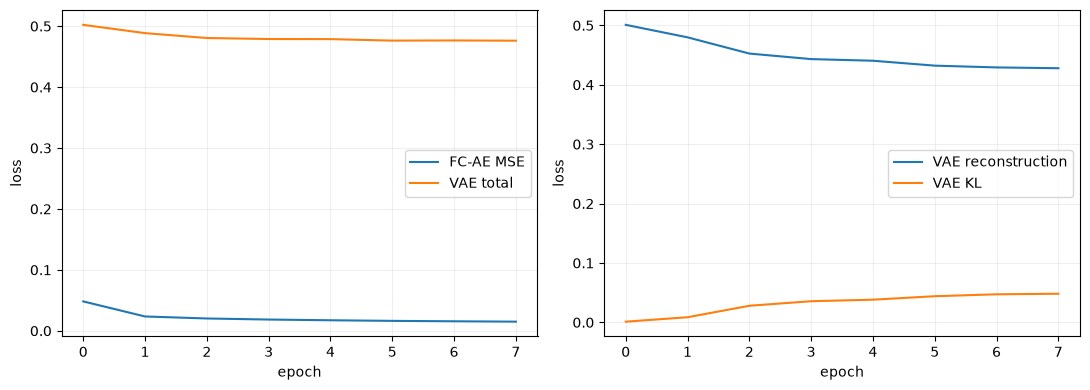

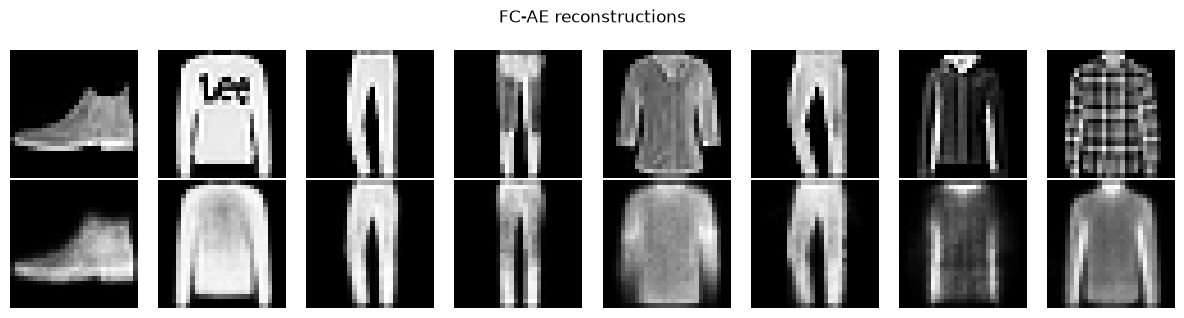

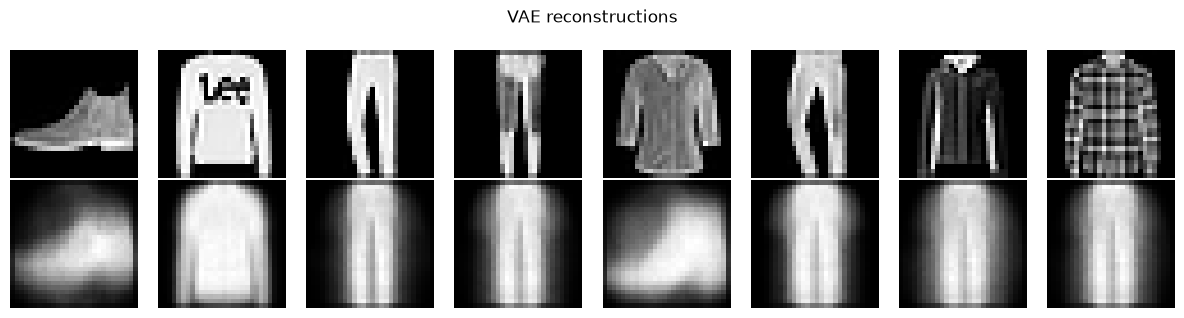

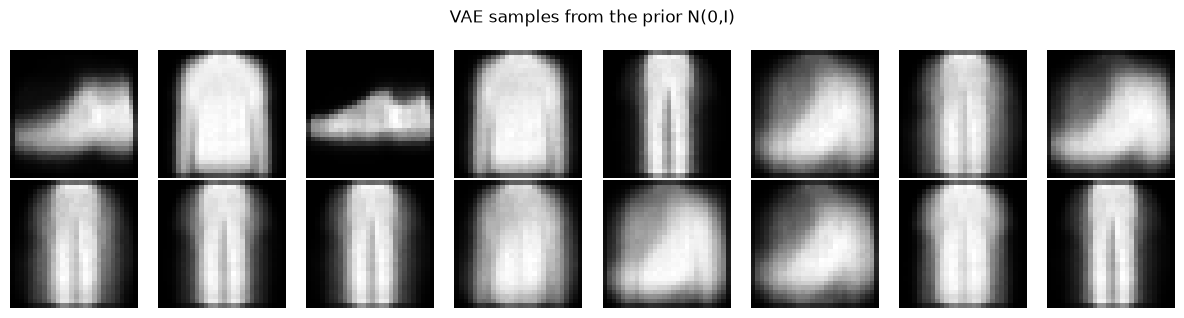

In [7]:
fig,ax=plt.subplots(1,2,figsize=(11,4)); ax[0].plot(fc_hist,label='FC-AE MSE'); ax[0].plot(vae_hist,label='VAE total'); ax[0].set(xlabel='epoch',ylabel='loss'); ax[0].legend(); ax[0].grid(alpha=.2); ax[1].plot(vae_rec_hist,label='VAE reconstruction'); ax[1].plot(vae_kl_hist,label='VAE KL'); ax[1].set(xlabel='epoch',ylabel='loss'); ax[1].legend(); ax[1].grid(alpha=.2); fig.tight_layout(); fig.savefig(FIG/'loss_curves.png',dpi=160); plt.show()
def show_recons(original,recon,title,path):
    fig,axes=plt.subplots(2,8,figsize=(12,3.2))
    for i in range(8): axes[0,i].imshow(original[i,0],cmap='gray'); axes[1,i].imshow(recon[i,0].clip(0,1),cmap='gray'); axes[0,i].axis('off'); axes[1,i].axis('off')
    axes[0,0].set_ylabel('real'); axes[1,0].set_ylabel('recon'); fig.suptitle(title); fig.tight_layout(); fig.savefig(path,dpi=160); plt.show()
show_recons(x_eval,fc_recon,'FC-AE reconstructions',FIG/'fc_reconstructions.png'); show_recons(x_eval,vae_recon,'VAE reconstructions',FIG/'vae_reconstructions.png')
with torch.no_grad(): samples=vae.decode(torch.randn(16,vae.latent_dim,device=DEVICE)).cpu()
fig,axes=plt.subplots(2,8,figsize=(12,3.2))
for i,ax in enumerate(axes.flat): ax.imshow(samples[i,0],cmap='gray'); ax.axis('off')
fig.suptitle('VAE samples from the prior N(0,I)'); fig.tight_layout(); fig.savefig(FIG/'vae_samples.png',dpi=160); plt.show()


Class-wise test MSE (lower is better):
0: T-shirt/top FC=0.013731 VAE=0.062027
1:   Trouser FC=0.008246 VAE=0.052524
2:  Pullover FC=0.014251 VAE=0.062361
3:     Dress FC=0.013937 VAE=0.056608
4:      Coat FC=0.013255 VAE=0.059924
5:    Sandal FC=0.022046 VAE=0.064541
6:     Shirt FC=0.014488 VAE=0.056522
7:   Sneaker FC=0.011815 VAE=0.045424
8:       Bag FC=0.022543 VAE=0.090844
9: Ankle boot FC=0.015065 VAE=0.074066


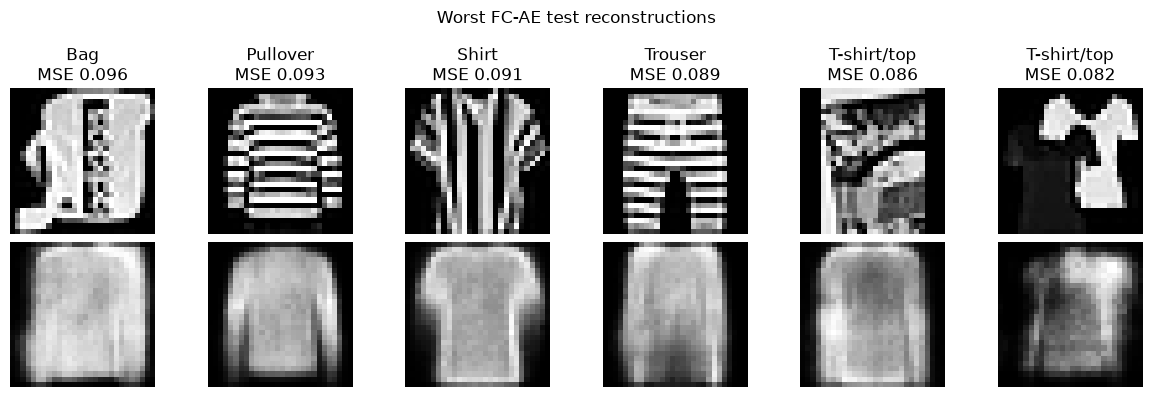

In [8]:
print('Class-wise test MSE (lower is better):')
for c,name in enumerate(class_names): print(f'{c}: {name:>9s} FC={fc_metrics["class_mse"][c]:.6f} VAE={vae_metrics["class_mse"][c]:.6f}')
@torch.no_grad()
def all_errors(model):
    model.eval(); rows=[]
    for x,y in test_loader:
        recon=model(x.to(DEVICE)); e=((recon-x.to(DEVICE))**2).flatten(1).mean(1).cpu(); rows.extend(zip(e.tolist(),x,recon.cpu(),y.tolist()))
    return sorted(rows,key=lambda r:r[0],reverse=True)
worst=all_errors(fc)[:6]; fig,axes=plt.subplots(2,6,figsize=(12,4))
for i,(err,x,r,y) in enumerate(worst):
    axes[0,i].imshow(x[0],cmap='gray'); axes[0,i].set_title(f'{class_names[y]}\nMSE {err:.3f}'); axes[1,i].imshow(r[0],cmap='gray'); axes[0,i].axis('off'); axes[1,i].axis('off')
axes[0,0].set_ylabel('real'); axes[1,0].set_ylabel('FC recon'); fig.suptitle('Worst FC-AE test reconstructions'); fig.tight_layout(); fig.savefig(FIG/'fc_worst6.png',dpi=160); plt.show()


In [9]:
results={'personal_parameters':{'SID4':SID4,'SEED':SEED,'SLICE':SLICE,'HP_ID':HP_ID,'CLS_A':CLS_A,'CLS_B':CLS_B},'device':str(DEVICE),'epochs':EPOCHS,'learning_rate':LR,'models':{'FC-AE':{**fc_metrics,'parameters':count_params(fc),'train_seconds':fc_time,'final_train_loss':fc_hist[-1]},'VAE':{**vae_metrics,'parameters':count_params(vae),'train_seconds':vae_time,'final_train_loss':vae_hist[-1],'final_reconstruction_loss':vae_rec_hist[-1],'final_kl_loss':vae_kl_hist[-1]}}}
with open(OUT/'results.json','w') as f: json.dump(results,f,indent=2)
torch.save(fc.state_dict(),CKPT/'fc_ae.pt'); torch.save(vae.state_dict(),CKPT/'vae.pt'); print(json.dumps(results,indent=2))


{
  "personal_parameters": {
    "SID4": 3215,
    "SEED": 3215,
    "SLICE": 215,
    "HP_ID": 5,
    "CLS_A": 5,
    "CLS_B": 2
  },
  "device": "mps",
  "epochs": 8,
  "learning_rate": 0.001,
  "models": {
    "FC-AE": {
      "test_mse": 0.014937776140868664,
      "test_psnr_db": 18.257139205932617,
      "class_mse": [
        0.013730586946010589,
        0.00824568772315979,
        0.014251341372728347,
        0.01393724536895752,
        0.013254653483629227,
        0.022046430468559267,
        0.014488258987665176,
        0.011815210551023483,
        0.022543312907218935,
        0.015065029561519623
      ],
      "parameters": 476720,
      "train_seconds": 23.740125750016887,
      "final_train_loss": 0.014989188204705715
    },
    "VAE": {
      "test_mse": 0.062484245747327805,
      "test_psnr_db": 12.0422945022583,
      "class_mse": [
        0.062026705503463744,
        0.05252440357208252,
        0.06236122715473175,
        0.05660836660861969,
        0.0

## Interpretation and limitations

The FC-AE only tries to reproduce each input image, so it gives the lower reconstruction error in this experiment. Its outputs can still look blurry when the original clothing item has soft or ambiguous edges. The VAE adds a KL term that keeps its latent codes close to a standard normal distribution. That makes it possible to generate new images from random latent vectors, but the extra regularization makes reconstruction less sharp. I use test MSE and PSNR to compare reconstruction quality, and I also check the error for each clothing class.

The worst examples are not always meaningless images. Pixel MSE is sensitive to small shifts and texture differences, and FashionMNIST is only 28 by 28 pixels. A better follow-up evaluation could include SSIM or a classifier-based perceptual score. I did not add a latent-size or KL-weight sweep because the assignment asks for the two model types rather than another hyperparameter comparison.
